# Gunpowder Flash (Mercenary)

Gunpowder Flash blinds the target with a burst of powder. For 30 s the target's **action
speed** (the speed row that gates attacks and other actions) drops by a number of points, and
the caster gets a 30 s haste. Enemies next to the caster that are attacking the caster are
slowed too. There is no resist roll and no cooldown.

The two halves scale differently. The slow is strong from the first point of skill and only
creeps up (6 → 8 points at mod 300), so at low levels the spell is mostly damage mitigation.
The haste starts at today's +3 and doubles by mod 300, so the caster's own speed is what grows.

| | |
|---|---|
| Class | Mercenary |
| Target | Selected enemy + caster's 4 cross neighbours **that are attacking the caster** |
| Cost | 7 mana (reduced by Concentration) |
| Cooldown | none; no exhaust |
| Landing roll | none: fails only on immortal targets or if power truncates to 0 |
| Duration | 30 s (slow on the target, haste on the caster) |
| Effect | target: `action_speed_calc −= slow`; caster: `action_speed_calc += haste_a`, `movement_speed_calc += haste_m` |
| Source | `server/src/driver/skill/mercenary.rs::skill_gunpowder_flash`, `gunpowder_flash_slow_points`, `gunpowder_flash_haste_points`; speed in `server/src/state/stats.rs::really_update_char` |

---

# Formula

The slow item stores $p' = \lfloor r\cdot\text{imm}(p, I)\rfloor$ (immunity $I$, caster race
multiplier $r$). The haste item stores the caster's raw modified skill $p$. Both use the shared
knee curve $K(p;\,a_0, a_{300})$, which is linear from $a_0$ at skill 0 to $a_{300}$ at mod 300
and continues at half that slope:

$$
\text{slow} = \operatorname{clamp}\!\left(K(p';\,6, 8),\ 6,\ 20\right)
\qquad
\text{haste}_a = K(p;\,3, 6)
\qquad
\text{haste}_m = K(p;\,1, 3)
$$

Speed is a row index into the 20×40 `SPEEDTAB`; row $k$ allows $20 - k$ advances per 40 ticks.
A swing takes 8 advances, so

$$
\text{row} = \operatorname{clamp}(20 - \text{calc},\ 0,\ 19)
\qquad
\text{attacks/s} = \frac{36\,(20 - \text{row})}{40 \cdot 8}
$$

where `calc` starts from the base speed $\lfloor(\text{AGI}+\text{STR})/50\rfloor + \text{speed\_mod}
+ 14$ (normal mode), plus attack-speed talents. The caster's haste adds $\text{haste}_a$ to the
action calc and $\text{haste}_m$ to the movement calc.

| Quantity | Breakpoint (Mercenary, immunity 0) |
|---|---|
| Slow | 6 below skill 143, 7 from 143, 8 from 286; 9 needs $p' \ge 600$ |
| Action haste | +3 below 100, +4 from 100, +5 from 200, +6 from 300 |
| Movement haste | +1 below 150, +2 from 150, +3 from 300 |
| Speed ceiling | calc above 20 is wasted (row 0); +6 is exactly what a base-14 caster needs |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
DURATION_S = 30
ENEMY_BASES = (14, 16, 18, 20, 22)

# Model

In [2]:
def flash_power(p, immun=0, race="Mercenary", moon=None):
    return mm.spell_power(p, immun, race, moon)


def slow_points(power):
    """`gunpowder_flash_slow_points(item.power)`."""
    return mm.clamp(mm.knee_300(power, 6, 8), 6, 20)


def haste_points(power):
    """`gunpowder_flash_haste_points(item.power)` -> (action, movement)."""
    return mm.knee_300(power, 3, 6), mm.knee_300(power, 1, 3)


def flash_slow(p, immun=0, race="Mercenary"):
    return slow_points(flash_power(p, immun, race))


def enemy_attacks_per_second(p, base, immun=0, race="Mercenary"):
    row = mm.action_speed_row(base, flash_slow=flash_slow(p, immun, race))
    return mm.attacks_per_second(row)


def caster_attacks_per_second(p, base):
    row = mm.action_speed_row(base, flash_haste=haste_points(p)[0])
    return mm.attacks_per_second(row)

# Validation

- `gunpowder_flash_slow_points_are_clamped`: power 0 → 6, 149 → 6, 150 → 7, 300 → 8, 600 → 9,
  100,000 → 20.
- `gunpowder_flash_haste_points_scale_past_the_slow`: power 0 → (3, 1), 150 → (4, 2),
  300 → (6, 3), 500 → (7, 3).
- `gunpowder_flash` speed tests in `stats.rs`: a Flash item of power 80 makes the action row
  slower, the Flash haste makes it faster, and a power-300 haste beats a power-1 haste.
- The cast costs 7 mana and both items last `TICKS*30`.
- `SPEEDTAB` row $k$ has exactly $20-k$ advances per 40 ticks.

In [3]:
assert [slow_points(x) for x in (0, 149, 150, 300, 600, 100_000)] == [6, 6, 7, 8, 9, 20]
assert [haste_points(x) for x in (0, 150, 300, 500)] == [(3, 1), (4, 2), (6, 3), (7, 3)]
assert mm.action_speed_row(18, flash_slow=slow_points(80)) > mm.action_speed_row(18)
assert mm.action_speed_row(14, flash_haste=haste_points(1)[0]) < mm.action_speed_row(14)
assert mm.action_speed_row(14, flash_haste=haste_points(300)[0]) < mm.action_speed_row(14, flash_haste=haste_points(1)[0])
assert mm.spell_cost(7) == 7 and mm.TICKS * DURATION_S == 1080
assert list(mm.SPEEDTAB.sum(axis=1)) == list(range(20, 0, -1))

assert flash_slow(142) == 6 and flash_slow(143) == 7     # p' 149 -> 6, p' 150 -> 7 (Mercenary)
assert flash_slow(285) == 7 and flash_slow(286) == 8
assert mm.action_speed_row(14, flash_haste=haste_points(300)[0]) == 0   # base-14 caster just reaches row 0
assert flash_power(10, immun=40, race="Templar") == 0    # immunity wall x 0.9 truncates to 0: cast fails
print("Gunpowder Flash model OK")

Gunpowder Flash model OK


# Plots

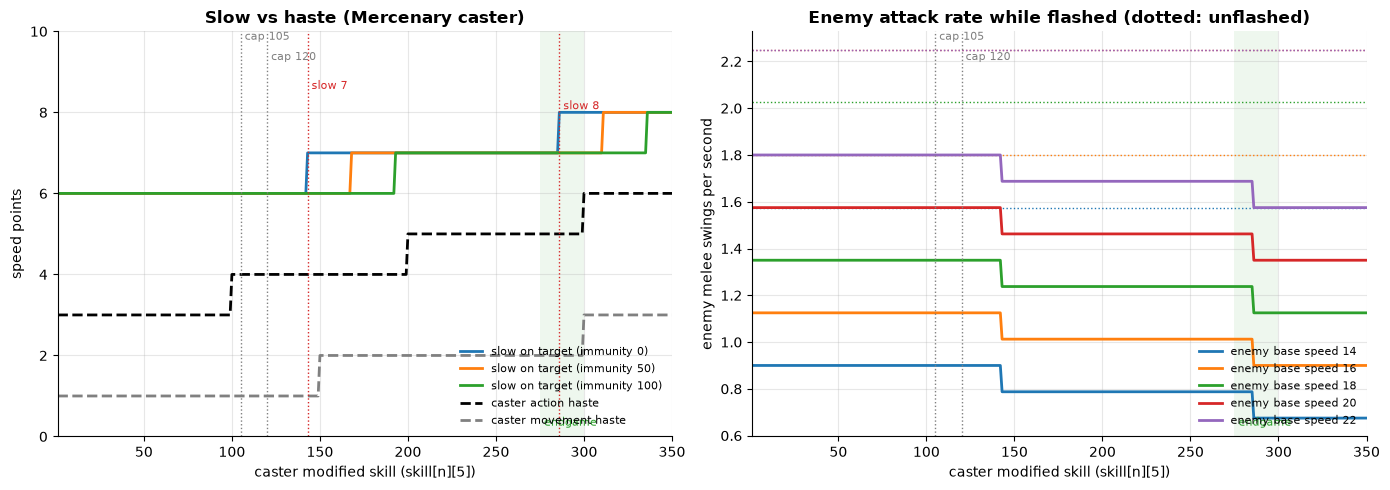

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for immun in (0, 50, 100):
    ax.plot(P, flash_slow(P, immun), label=f"slow on target (immunity {immun})")
haste_a, haste_m = haste_points(P)
ax.plot(P, haste_a, color="black", ls="--", label="caster action haste")
ax.plot(P, haste_m, color="grey", ls="--", label="caster movement haste")
mm.skill_axis(ax, "speed points", "Slow vs haste (Mercenary caster)")
ax.set_ylim(0, 10)
mm.mark_caps(ax, extra=[(143, "slow 7"), (286, "slow 8")])
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
for base in ENEMY_BASES:
    line, = ax.plot(P, enemy_attacks_per_second(P, base), label=f"enemy base speed {base}")
    ax.axhline(mm.attacks_per_second(mm.action_speed_row(base)), color=line.get_color(), ls=":", lw=1)
mm.skill_axis(ax, "enemy melee swings per second", "Enemy attack rate while flashed (dotted: unflashed)")
mm.mark_caps(ax)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()

The slow is nearly flat: 6 points from skill 1, 7 at 143 and 8 at 286. Even a skill-1 Flash
takes a third of a base-18 enemy's swings away. The haste doubles over the same range. Against
immunity 50–100 the slow reaches 8 only past mod 300. Each point of enemy base speed above 20
is wasted while the enemy is unaffected, but it soaks up a point of the slow.

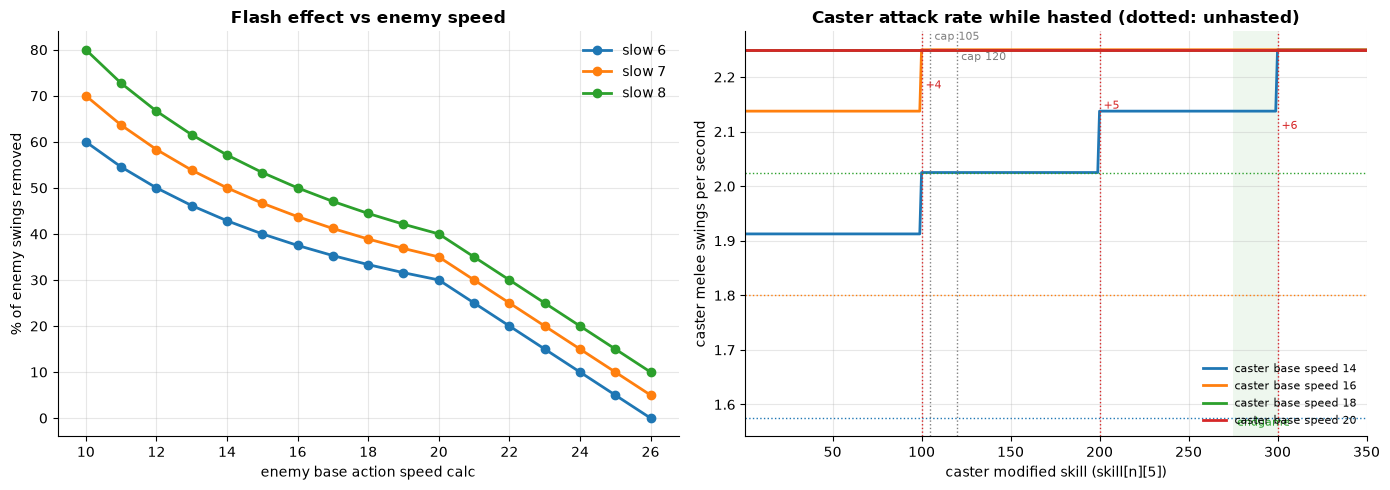

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Relative slow vs enemy base speed for the slow values reachable up to mod 350.
ax = axes[0]
bases = np.arange(10, 27)
for slow in (6, 7, 8):
    before = mm.attacks_per_second(mm.action_speed_row(bases))
    after = mm.attacks_per_second(mm.action_speed_row(bases, flash_slow=slow))
    ax.plot(bases, 100 * (1 - after / before), marker="o", label=f"slow {slow}")
ax.set_xlabel("enemy base action speed calc")
ax.set_ylabel("% of enemy swings removed")
ax.set_title("Flash effect vs enemy speed")
ax.legend()

# Caster swings per second vs skill, for several caster base speeds.
ax = axes[1]
for base in (14, 16, 18, 20):
    line, = ax.plot(P, caster_attacks_per_second(P, base), label=f"caster base speed {base}")
    ax.axhline(mm.attacks_per_second(mm.action_speed_row(base)), color=line.get_color(), ls=":", lw=1)
mm.skill_axis(ax, "caster melee swings per second", "Caster attack rate while hasted (dotted: unhasted)")
mm.mark_caps(ax, extra=[(100, "+4"), (200, "+5"), (300, "+6")])
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()

# Observations

- At low skill the spell is mostly a defensive tool. A 6-point slow removes 33% of a base-18
  enemy's swings (2.02 → 1.35 per second) and 43% of a base-14 enemy's (1.57 → 0.90), from
  skill 1. It lasts 30 s, with no resist roll and no cooldown, and also hits every cross
  neighbour attacking the caster. Only immortality or Seeing Red stops it.
- The slow only creeps up. At mod 300 (8 points) it removes 44% of a base-18 enemy's swings
  instead of 33%. Against immunity 50 or more it is still 7 at mod 300.
- A base-22 enemy, two points of "wasted" speed, loses 20% of its swings to a 6-point slow and
  30% to an 8-point slow. Excess speed above 20 acts as hidden Flash resistance.
- The haste is the part that grows: +3/+1 at the floor, +6/+3 at mod 300. A base-14 caster goes
  from 1.91 to 2.25 swings per second (row 0) across that range.
- The speed ceiling caps the haste. A base-16 caster is capped at +4 (skill 100), and a base-18
  caster is already capped at +3. A caster with a base action calc of 20 or more, which needs
  AGI + STR ≥ 300 in normal mode or ≥ 200 in fast mode, gets no attack speed from the haste.
  Movement haste follows the same rule on the movement row. For most endgame builds the extra
  haste only offsets other slows, because the calc is summed before the row clamp.
- `apply_gunpowder_flash` fails when $p' < 1$. That can only happen when the immunity wall
  reduces the power to 1 and the race multiplier is below 1, for example a Templar or Seyan'Du
  caster (×0.9/×0.95) or a new moon (−0.15).